<a href="https://colab.research.google.com/github/Erick88santos/Dataset_shark_anotation/blob/main/ESTUDO_DE_CASO_DRONESHARK_BINARIO_5FOLD.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Estudo de Caso — DroneShark Dataset
## Detecção binária: tubarão ou não-tubarão com validação cruzada 5-Fold

Este notebook reorganiza o experimento original para a proposta **mais simples**, definida em reunião com o orientador: em vez de comparar múltiplas classes (banhista, surfista, tubarão) e condições visuais (fácil/moderada/difícil), o modelo passa a resolver um único problema:

> **Há um tubarão na imagem, ou não?**

O detector utilizado é o **YOLO11s**, configurado para uma única classe (`shark`). As demais classes do dataset original são removidas das anotações. As imagens que não contêm tubarão permanecem no conjunto como **imagens de fundo (background)**, com arquivo de label vazio, representando os exemplos negativos da decisão "não-tubarão".

### Protocolo experimental definido para este estudo

A avaliação será realizada por **validação cruzada estratificada em 5 folds (5-Fold Cross-Validation)**. Em cada rodada:

- **4 folds** são destinados ao desenvolvimento do modelo;
- **1 fold** é reservado exclusivamente para **teste**;
- o fold de teste muda a cada rodada, até que todos os folds tenham sido utilizados uma vez como teste.

Para que o YOLO disponha de um conjunto de validação durante o treinamento, os **4 folds de desenvolvimento** são divididos internamente em treino e validação. Essa validação interna **não utiliza o fold de teste**.

Assim, a lógica principal segue o formato proposto pelo orientador:

**Rodada 1:** Treino | Treino | Treino | Treino | **Teste**  
**Rodada 2:** Treino | Treino | Treino | **Teste** | Treino  
**Rodada 3:** Treino | Treino | **Teste** | Treino | Treino  
**Rodada 4:** Treino | **Teste** | Treino | Treino | Treino  
**Rodada 5:** **Teste** | Treino | Treino | Treino | Treino

Ao final, os resultados das cinco rodadas são agregados para obter uma estimativa mais robusta do desempenho do detector.

**Importante:** cada imagem aparece no conjunto de teste exatamente uma vez ao longo das cinco rodadas.


## 1. Configuração do ambiente

Esta célula instala as bibliotecas utilizadas no experimento.


In [1]:
# Instalação das bibliotecas
!pip install -q ultralytics opencv-python pandas matplotlib seaborn pyyaml

# Se estiver usando Google Drive, descomente:
# from google.colab import drive
# drive.mount('/content/drive')


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.2/46.2 kB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 44.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.2/53.2 kB 3.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 67.7/67.7 kB 6.0 MB/s eta 0:00:00


In [2]:
# Importações e configuração reprodutível
import os
import random
import shutil
import zipfile
import glob
import yaml
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from collections import Counter
from ultralytics import YOLO

SEED = 42
N_FOLDS = 5
random.seed(SEED)
np.random.seed(SEED)

print("Ambiente configurado.")
print(f"Seed: {SEED}")
print(f"Número de folds: {N_FOLDS}")


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart#ultralytics-settings.
Ambiente configurado.
Seed: 42
Número de folds: 5


## 2. Verificação da GPU

O treinamento será executado no Google Colab utilizando GPU quando disponível.


In [1]:
!nvidia-smi


Mon Sep  7 16:41:21 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   45C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA disponível:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("ATENÇÃO: GPU não disponível. No Colab, selecione Runtime > Change runtime type > GPU.")


PyTorch: 2.11.0+cu128
CUDA disponível: True
GPU: Tesla T4


## 3. Localização do dataset

### Opção A — dataset já está em `/content`

Se você já possui uma pasta com `images/` e `labels/`, altere `SOURCE_DATASET`.

### Opção B — dataset em arquivo ZIP

Execute a célula de upload e envie o `.zip` do DroneShark Dataset.

A estrutura esperada da fonte é:

```text
fonte_do_dataset/
├── images/
│   ├── imagem1.jpg
│   ├── imagem2.jpg
│   └── ...
└── labels/
    ├── imagem1.txt
    ├── imagem2.txt
    └── ...
```

O script também procura automaticamente uma pasta contendo `images/` e `labels/` dentro do diretório extraído.


In [3]:
# ===== CONFIGURAÇÃO =====

ZIP_FILE_PATH = "/content/YOLO_DATA.zip"

EXTRACTED_DATASET_ROOT = "/content/droneshark_dataset_extracted"

SOURCE_DATASET = EXTRACTED_DATASET_ROOT

# Dataset binário final: apenas shark + imagens de fundo
DATASET = "/content/dataset_shark_binary_5fold"

# Diretório dos resultados das cinco rodadas
RESULTS_ROOT = "/content/results/drone_shark_binary_5fold"

print("ZIP_FILE_PATH:", ZIP_FILE_PATH)
print("EXTRACTED_DATASET_ROOT:", EXTRACTED_DATASET_ROOT)
print("DATASET:", DATASET)
print("RESULTS_ROOT:", RESULTS_ROOT)


ZIP_FILE_PATH: /content/YOLO_DATA.zip
EXTRACTED_DATASET_ROOT: /content/droneshark_dataset_extracted
DATASET: /content/dataset_shark_binary_5fold
RESULTS_ROOT: /content/results/drone_shark_binary_5fold


In [5]:
# ===== EXTRAÇÃO/VERIFICAÇÃO DO DATASET =====

from google.colab import files
import os
from pathlib import Path
import zipfile

def find_dataset_root(base_path):
    base_path = Path(base_path)

    if base_path.is_dir() and (base_path / "images").is_dir() and (base_path / "labels").is_dir():
        return str(base_path)

    for root, dirs, _ in os.walk(base_path):
        root_path = Path(root)
        if (root_path / "images").is_dir() and (root_path / "labels").is_dir():
            return str(root_path)

    return None

if not os.path.exists(EXTRACTED_DATASET_ROOT):
    if not os.path.exists(ZIP_FILE_PATH):
        print("Envie o arquivo ZIP do dataset:")
        uploaded = files.upload()
        ZIP_FILE_PATH = list(uploaded.keys())[0]

    print(f"Extraindo dataset de {ZIP_FILE_PATH} para {EXTRACTED_DATASET_ROOT}...")
    with zipfile.ZipFile(ZIP_FILE_PATH, "r") as zip_ref:
        zip_ref.extractall(EXTRACTED_DATASET_ROOT)

found_root = find_dataset_root(EXTRACTED_DATASET_ROOT)

if found_root is None:
    raise FileNotFoundError(
        "Não foi possível localizar pastas 'images' e 'labels' dentro do dataset extraído."
    )

SOURCE_DATASET = found_root
print("Dataset encontrado em:", SOURCE_DATASET)


Extraindo dataset de /content/YOLO_DATA.zip para /content/droneshark_dataset_extracted...
Dataset encontrado em: /content/droneshark_dataset_extracted


## 4. Filtragem para classe única: tubarão (shark)

Esta é a principal simplificação em relação ao estudo original.

Cada arquivo de anotação (`.txt` no formato YOLO) é reescrito:

- linhas cuja classe corresponde a **shark** são mantidas e remapeadas para a classe `0`;
- todas as demais linhas (banhista, surfista, outros animais) são removidas;
- imagens que ficam **sem nenhuma linha** após a filtragem não são descartadas — permanecem como **imagens de fundo**, representando a situação "não-tubarão".

**Ajuste `RAW_SHARK_CLASS_ID` conforme o `data.yaml`/anotações originais do seu ZIP.** No dataset utilizado neste estudo, o id bruto de tubarão é `3`.


In [6]:
# ===== LOCALIZAR PARES IMAGEM/LABEL NA FONTE =====

IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def find_image_label_pairs(root):
    root = Path(root)

    image_files = [
        p for p in root.rglob("*")
        if p.is_file()
        and p.suffix.lower() in IMAGE_EXTS
        and "images" in [part.lower() for part in p.parts]
    ]

    pairs = []
    missing = []

    for img in image_files:
        parts = list(img.parts)
        idx = [p.lower() for p in parts].index("images")
        label_parts = parts[:idx] + ["labels"] + parts[idx + 1:]
        label_path = Path(*label_parts).with_suffix(".txt")

        if label_path.exists():
            pairs.append((img, label_path))
        else:
            missing.append(img)

    return pairs, missing

pairs, missing = find_image_label_pairs(SOURCE_DATASET)

print("Pares imagem/label encontrados:", len(pairs))
print("Imagens sem label:", len(missing))

if missing:
    print("Exemplos de imagens sem label:")
    for p in missing[:5]:
        print(" -", p)


Pares imagem/label encontrados: 534
Imagens sem label: 0


In [8]:
# ===== FILTRAGEM: MANTER APENAS A CLASSE SHARK, REMAPEADA PARA 0 =====

import shutil
from pathlib import Path

RAW_SHARK_CLASS_ID = 3

OUTPUT_DIR = Path(DATASET)
OUTPUT_IMAGES = OUTPUT_DIR / "images"
OUTPUT_LABELS = OUTPUT_DIR / "labels"

if OUTPUT_DIR.exists():
    shutil.rmtree(OUTPUT_DIR)

OUTPUT_IMAGES.mkdir(parents=True, exist_ok=True)
OUTPUT_LABELS.mkdir(parents=True, exist_ok=True)

CLASS_NAMES = ["shark"]

n_with_shark = 0
n_background = 0
total_shark_instances = 0
invalid_source_lines = 0

for img_path, label_path in pairs:
    lines = label_path.read_text(encoding="utf-8").strip().splitlines()

    kept_lines = []

    for line in lines:
        line = line.strip()
        if not line:
            continue

        parts = line.split()

        if len(parts) != 5:
            invalid_source_lines += 1
            continue

        try:
            cls = int(float(parts[0]))
        except ValueError:
            invalid_source_lines += 1
            continue

        if cls == RAW_SHARK_CLASS_ID:
            coords = parts[1:]
            kept_lines.append("0 " + " ".join(coords))

    # Mantém todas as imagens.
    dest_img = OUTPUT_IMAGES / img_path.name
    shutil.copy2(img_path, dest_img)

    # Label vazio = imagem de fundo / não-tubarão.
    dest_label = OUTPUT_LABELS / f"{img_path.stem}.txt"
    dest_label.write_text("\n".join(kept_lines), encoding="utf-8")

    if kept_lines:
        n_with_shark += 1
        total_shark_instances += len(kept_lines)
    else:
        n_background += 1

print("============================================================")
print("DATASET BINÁRIO — CLASSE ÚNICA (shark)")
print("============================================================")
print(f"Total de imagens processadas: {len(pairs)}")
print(f"Imagens com tubarão: {n_with_shark}")
print(f"Imagens sem tubarão (background): {n_background}")
print(f"Total de instâncias de tubarão mantidas: {total_shark_instances}")
print(f"Linhas inválidas ignoradas na fonte: {invalid_source_lines}")
print(f"Dataset final: {OUTPUT_DIR}")


DATASET BINÁRIO — CLASSE ÚNICA (shark)
Total de imagens processadas: 534
Imagens com tubarão: 446
Imagens sem tubarão (background): 88
Total de instâncias de tubarão mantidas: 812
Linhas inválidas ignoradas na fonte: 0
Dataset final: /content/dataset_shark_binary_5fold


In [9]:
# ===== VALIDAÇÃO DO DATASET FILTRADO =====

invalid_labels = []
empty_labels = 0
total_label_files = 0
instance_count = 0

for label_path in OUTPUT_LABELS.glob("*.txt"):
    total_label_files += 1

    text = label_path.read_text(encoding="utf-8").strip()
    lines = text.splitlines() if text else []

    if not lines:
        empty_labels += 1
        continue

    for line in lines:
        parts = line.split()

        if len(parts) != 5:
            invalid_labels.append((label_path.name, line, "Formato inválido"))
            continue

        try:
            cls = int(float(parts[0]))
            coords = [float(x) for x in parts[1:]]
        except ValueError:
            invalid_labels.append((label_path.name, line, "Valor não numérico"))
            continue

        if cls != 0:
            invalid_labels.append((label_path.name, line, "Classe inesperada (esperado 0)"))
            continue

        if any(c < 0.0 or c > 1.0 for c in coords):
            invalid_labels.append(
                (label_path.name, line, "Coordenadas fora do intervalo [0,1]")
            )
            continue

        instance_count += 1

print("============================================================")
print("VALIDAÇÃO FINAL DO DATASET BINÁRIO")
print("============================================================")
print(f"Arquivos de labels: {total_label_files}")
print(f"Labels vazios (não-tubarão/background): {empty_labels}")
print(f"Instâncias válidas de tubarão: {instance_count}")
print(f"Anotações inválidas: {len(invalid_labels)}")

if invalid_labels:
    print("\nExemplos de anotações inválidas:")
    for item in invalid_labels[:5]:
        print(item)
else:
    print("\n✅ DATASET VALIDADO COM SUCESSO!")


VALIDAÇÃO FINAL DO DATASET BINÁRIO
Arquivos de labels: 534
Labels vazios (não-tubarão/background): 88
Instâncias válidas de tubarão: 808
Anotações inválidas: 4

Exemplos de anotações inválidas:
('95c5fbf5-00621.txt', '0 0.49159579020807703 1.172674944304481 0.16502575616951834 0.630196936542675', 'Coordenadas fora do intervalo [0,1]')
('5e88bcfa-00593.txt', '0 0.7300035026674543 1.0431454941219767 0.15497366594300685 0.545924338030236', 'Coordenadas fora do intervalo [0,1]')
('876f2af9-00216.txt', '0 0.7581150614338906 1.0335302131046256 0.06499999999999972 0.32966960750717106', 'Coordenadas fora do intervalo [0,1]')
('26bb7808-00605.txt', '0 0.3195663266135246 1.1622447637798778 0.20758861278614305 0.5738364298027224', 'Coordenadas fora do intervalo [0,1]')


## 5. Validação cruzada estratificada em 5 folds

A divisão segue a estrutura apresentada pelo orientador.

Em cada rodada, um dos cinco folds é utilizado **exclusivamente como teste**, enquanto os outros quatro são utilizados para desenvolvimento do modelo.

Para reduzir variações na proporção de imagens com e sem tubarão, a criação dos folds é **estratificada por presença/ausência de tubarão**.

### Esquema experimental

| Rodada | Fold 1 | Fold 2 | Fold 3 | Fold 4 | Fold 5 |
|---|---|---|---|---|---|
| 1 | Treino | Treino | Treino | Treino | **Teste** |
| 2 | Treino | Treino | Treino | **Teste** | Treino |
| 3 | Treino | Treino | **Teste** | Treino | Treino |
| 4 | Treino | **Teste** | Treino | Treino | Treino |
| 5 | **Teste** | Treino | Treino | Treino | Treino |

**Observação metodológica:** para permitir early stopping e seleção do melhor checkpoint durante o treinamento do YOLO, os quatro folds de desenvolvimento de cada rodada são divididos internamente em `train` e `val`. O fold externo de teste nunca é utilizado nessa etapa.


In [12]:
import random

SEED = 42
N_FOLDS = 5

# ===== CRIAÇÃO DOS 5 FOLDS ESTRATIFICADOS =====

all_items = [
    (p, OUTPUT_LABELS / f"{p.stem}.txt")
    for p in sorted(OUTPUT_IMAGES.iterdir())
    if p.is_file() and p.suffix.lower() in IMAGE_EXTS
]

def is_positive(label_path):
    return bool(label_path.read_text(encoding="utf-8").strip())

positive_items = [item for item in all_items if is_positive(item[1])]
negative_items = [item for item in all_items if not is_positive(item[1])]

rng = random.Random(SEED)
rng.shuffle(positive_items)
rng.shuffle(negative_items)

folds = [[] for _ in range(N_FOLDS)]

# Distribuição round-robin para manter aproximadamente a proporção positiva/negativa.
for idx, item in enumerate(positive_items):
    folds[idx % N_FOLDS].append(item)

for idx, item in enumerate(negative_items):
    folds[idx % N_FOLDS].append(item)

for fold in folds:
    fold.sort(key=lambda x: x[0].name)

print("============================================================")
print("DISTRIBUIÇÃO DOS 5 FOLDS")
print("============================================================")

for i, fold in enumerate(folds, start=1):
    pos = sum(is_positive(lp) for _, lp in fold)
    neg = len(fold) - pos
    print(f"Fold {i}: {len(fold)} imagens | {pos} com tubarão | {neg} sem tubarão")

assert sum(len(fold) for fold in folds) == len(all_items)
assert all(len(fold) > 0 for fold in folds)


DISTRIBUIÇÃO DOS 5 FOLDS
Fold 1: 108 imagens | 90 com tubarão | 18 sem tubarão
Fold 2: 107 imagens | 89 com tubarão | 18 sem tubarão
Fold 3: 107 imagens | 89 com tubarão | 18 sem tubarão
Fold 4: 106 imagens | 89 com tubarão | 17 sem tubarão
Fold 5: 106 imagens | 89 com tubarão | 17 sem tubarão


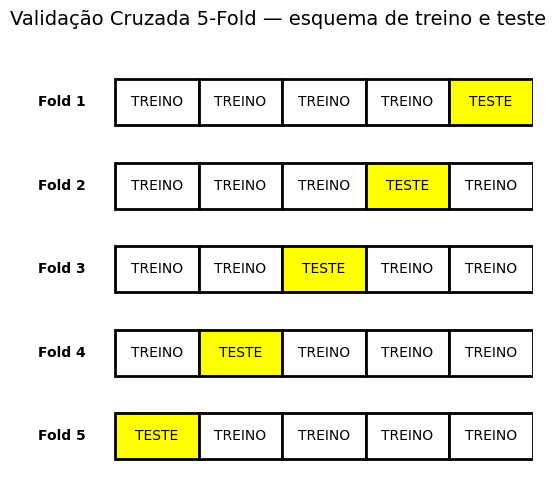

In [14]:
import matplotlib.pyplot as plt

# ===== VISUALIZAÇÃO DO ESQUEMA 5-FOLD =====
# A figura reproduz a lógica apresentada pelo orientador:
# em cada rodada, um único fold é reservado para TESTE.

fig, ax = plt.subplots(figsize=(12, 5))
ax.axis("off")

for row in range(N_FOLDS):
    y = N_FOLDS - row - 1

    for col in range(N_FOLDS):
        x = col
        is_test = (col == N_FOLDS - row - 1)

        rect = plt.Rectangle(
            (x, y),
            1,
            0.55,
            facecolor="yellow" if is_test else "white",
            edgecolor="black",
            linewidth=2
        )
        ax.add_patch(rect)

        label = "TESTE" if is_test else "TREINO"
        ax.text(
            x + 0.5,
            y + 0.275,
            label,
            ha="center",
            va="center",
            fontsize=10
        )

    ax.text(
        -0.35,
        y + 0.275,
        f"Fold {row + 1}",
        ha="right",
        va="center",
        fontsize=10,
        fontweight="bold"
    )

ax.set_xlim(-1.1, N_FOLDS)
ax.set_ylim(-0.25, N_FOLDS + 0.1)
ax.set_aspect("equal")
ax.set_title("Validação Cruzada 5-Fold — esquema de treino e teste", fontsize=14)
plt.tight_layout()
plt.show()

## 6. Preparação dos conjuntos de cada rodada

Nesta etapa são criadas as pastas temporárias utilizadas pelo YOLO em cada fold.

Para cada rodada:

- **Teste externo:** 1 fold inteiro;
- **Desenvolvimento:** os outros 4 folds;
- **Treino interno:** 80% do desenvolvimento;
- **Validação interna:** 20% do desenvolvimento.

O conjunto de teste externo permanece intocado até a avaliação daquela rodada.


In [16]:
import yaml
import shutil
from pathlib import Path
import random

# ===== FUNÇÕES PARA PREPARAR CADA RODADA =====

CV_ROOT = Path(DATASET) / "cv_folds"

if CV_ROOT.exists():
    shutil.rmtree(CV_ROOT)

CV_ROOT.mkdir(parents=True, exist_ok=True)

INTERNAL_TRAIN_RATIO = 0.80

def copy_split(items, images_dir, labels_dir):
    images_dir.mkdir(parents=True, exist_ok=True)
    labels_dir.mkdir(parents=True, exist_ok=True)

    for img_path, label_path in items:
        shutil.copy2(img_path, images_dir / img_path.name)
        shutil.copy2(label_path, labels_dir / label_path.name)

def prepare_fold(fold_index):
    # fold_index: 0..4
    test_items = folds[fold_index]
    development_items = [
        item
        for i, fold in enumerate(folds)
        if i != fold_index
        for item in fold
    ]

    # Estratificação interna por presença/ausência de tubarão.
    pos_dev = [item for item in development_items if is_positive(item[1])]
    neg_dev = [item for item in development_items if not is_positive(item[1])]

    local_rng = random.Random(SEED + fold_index)
    local_rng.shuffle(pos_dev)
    local_rng.shuffle(neg_dev)

    def split_internal(items):
        cut = int(len(items) * INTERNAL_TRAIN_RATIO)
        return items[:cut], items[cut:]

    pos_train, pos_val = split_internal(pos_dev)
    neg_train, neg_val = split_internal(neg_dev)

    train_items = pos_train + neg_train
    val_items = pos_val + neg_val

    local_rng.shuffle(train_items)
    local_rng.shuffle(val_items)

    fold_root = CV_ROOT / f"fold_{fold_index + 1}"

    split_items = {
        "train": train_items,
        "val": val_items,
        "test": test_items,
    }

    for split_name, items in split_items.items():
        copy_split(
            items,
            fold_root / "images" / split_name,
            fold_root / "labels" / split_name
        )

    yaml_path = fold_root / "data.yaml"

    yaml_data = {
        "path": str(fold_root),
        "train": "images/train",
        "val": "images/val",
        "test": "images/test",
        "nc": len(CLASS_NAMES),
        "names": CLASS_NAMES
    }

    with open(yaml_path, "w", encoding="utf-8") as f:
        yaml.safe_dump(
            yaml_data,
            f,
            sort_keys=False,
            allow_unicode=True
        )

    return fold_root, yaml_path, split_items

fold_configs = []

for fold_index in range(N_FOLDS):
    fold_root, yaml_path, split_items = prepare_fold(fold_index)
    fold_configs.append({
        "fold": fold_index + 1,
        "root": fold_root,
        "yaml": yaml_path,
        "splits": split_items
    })

    print(
        f"Fold {fold_index + 1}: "
        f"train={len(split_items['train'])}, "
        f"val={len(split_items['val'])}, "
        f"test={len(split_items['test'])}"
    )


Fold 1: train=340, val=86, test=108
Fold 2: train=341, val=86, test=107
Fold 3: train=341, val=86, test=107
Fold 4: train=341, val=87, test=106
Fold 5: train=341, val=87, test=106


## 7. Conferência visual da base

Antes do treinamento, algumas imagens de cada rodada podem ser visualizadas com suas anotações.

As imagens sem caixas representam explicitamente o grupo **não-tubarão/background**.


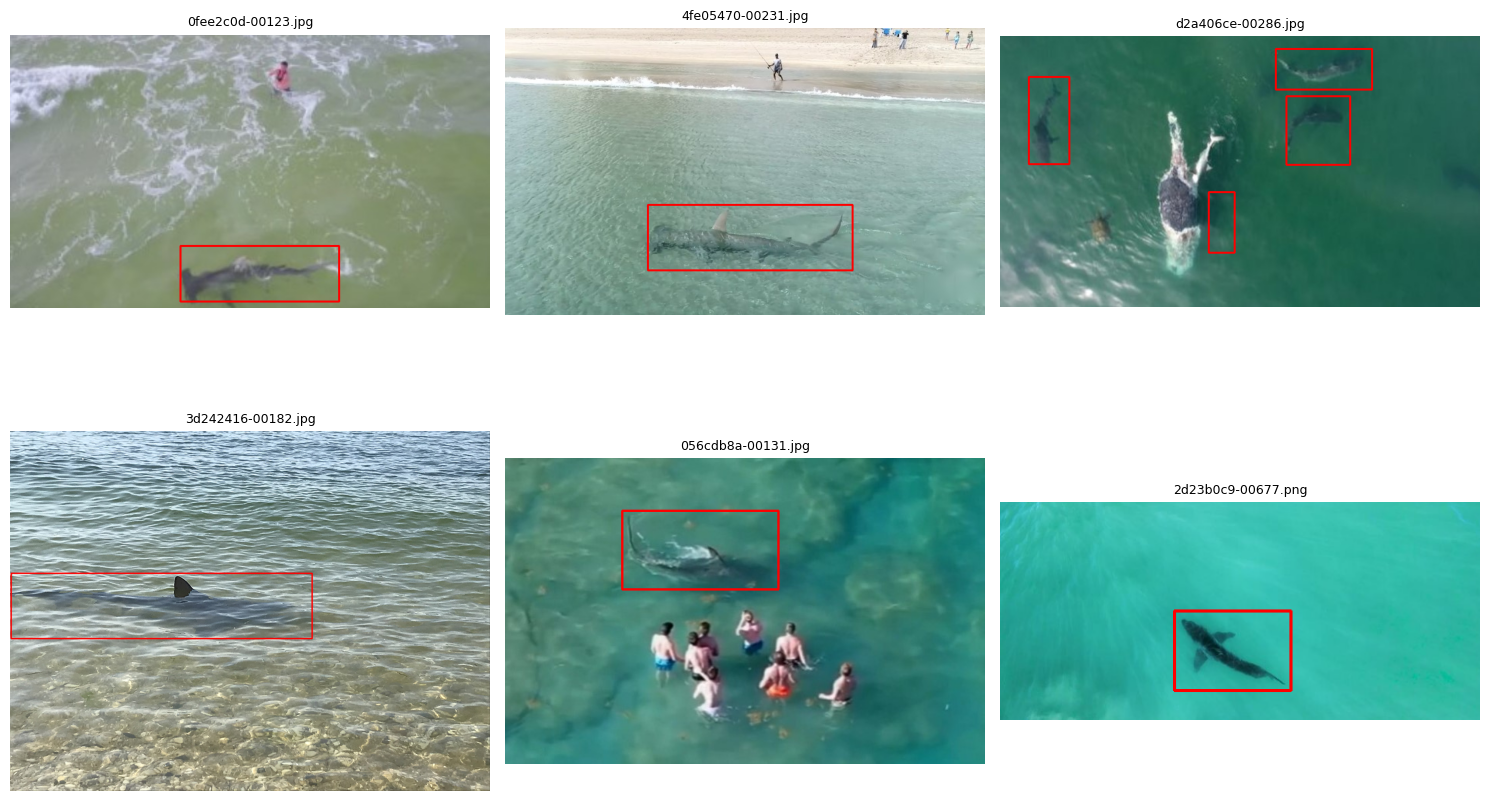

In [20]:
import math
import numpy as np
import cv2

# ===== VISUALIZAÇÃO DE AMOSTRAS =====

def show_samples(fold_number=1, split="train", n=6):
    fold_root = CV_ROOT / f"fold_{fold_number}"
    image_dir = fold_root / "images" / split
    label_dir = fold_root / "labels" / split

    image_files = [
        p for p in image_dir.iterdir()
        if p.suffix.lower() in IMAGE_EXTS
    ]

    random.Random(SEED + fold_number).shuffle(image_files)
    image_files = image_files[:n]

    if not image_files:
        print(f"Nenhuma imagem encontrada em fold_{fold_number}/{split}.")
        return

    rows = math.ceil(len(image_files) / 3)
    fig, axes = plt.subplots(rows, 3, figsize=(15, 5 * rows))
    axes = np.array(axes).reshape(-1)

    for ax in axes:
        ax.axis("off")

    for ax, img_path in zip(axes, image_files):
        img_bgr = cv2.imread(str(img_path))

        if img_bgr is None:
            ax.set_title(f"Erro ao ler {img_path.name}")
            continue

        img = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
        h, w = img.shape[:2]

        label_path = label_dir / f"{img_path.stem}.txt"
        text = label_path.read_text(encoding="utf-8").strip() if label_path.exists() else ""
        lines = text.splitlines() if text else []

        for line in lines:
            _, xc, yc, bw, bh = map(float, line.split())

            x1 = int((xc - bw / 2) * w)
            y1 = int((yc - bh / 2) * h)
            x2 = int((xc + bw / 2) * w)
            y2 = int((yc + bh / 2) * h)

            cv2.rectangle(img, (x1, y1), (x2, y2), (255, 0, 0), 2)

        title = img_path.name if lines else f"{img_path.name} (não-tubarão)"
        ax.imshow(img)
        ax.set_title(title, fontsize=9)
        ax.axis("off")

    plt.tight_layout()
    plt.show()

show_samples(fold_number=1, split="train", n=6)

## 8. Treinamento do YOLO11s — 5-Fold Cross-Validation

O mesmo modelo **YOLO11s** e os mesmos hiperparâmetros são utilizados nas cinco rodadas.

A única alteração entre as rodadas é quais imagens pertencem ao conjunto de teste externo.

Não se escolhe um modelo diferente para cada condição: o objetivo é medir a capacidade do mesmo detector de reconhecer a presença de tubarões.


In [24]:
!pip install ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.2/46.2 kB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 40.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 68.9/68.9 kB 7.6 MB/s eta 0:00:00


In [25]:
from ultralytics import YOLO

# ===== TREINAMENTO DOS 5 FOLDS =====

EPOCHS = 100
IMGSZ = 640
BATCH = 16
WORKERS = 0
PATIENCE = 20

fold_training_info = []

for fold_cfg in fold_configs:
    fold_number = fold_cfg["fold"]
    data_yaml = str(fold_cfg["yaml"])

    run_name = f"fold_{fold_number}"

    print("\n" + "=" * 70)
    print(f"TREINAMENTO — FOLD {fold_number}/{N_FOLDS}")
    print("=" * 70)

    model = YOLO("yolo11s.pt")

    results = model.train(
        data=data_yaml,
        epochs=EPOCHS,
        imgsz=IMGSZ,
        batch=BATCH,
        workers=WORKERS,
        patience=PATIENCE,
        seed=SEED,
        project=RESULTS_ROOT,
        name=run_name,
        exist_ok=True,
        device=0
    )

    best_model_path = Path(RESULTS_ROOT) / run_name / "weights" / "best.pt"

    fold_training_info.append({
        "fold": fold_number,
        "best_model": str(best_model_path)
    })

    print("Melhor modelo:", best_model_path)

print("\nTreinamento dos 5 folds concluído.")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart#ultralytics-settings.

TREINAMENTO — FOLD 1/5
Ultralytics 8.4.142 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset_shark_binary_5fold/cv_folds/fold_1/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4,

## 9. Curvas de treinamento

Cada rodada possui seu próprio `results.csv`.

As curvas permitem verificar a evolução do treinamento e comparar a estabilidade das cinco execuções.


Fold 1 — últimas épocas:


,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
79,80,998.204,1.37271,1.06938,1.40324,0.61882,0.49107,0.48913,0.21375,2.06114,1.56449,1.92301,0.000436,0.000436,0.000436
80,81,1010.680,1.44285,1.05993,1.43542,0.58883,0.46429,0.49238,0.22504,2.01725,1.56073,1.90597,0.000416,0.000416,0.000416
81,82,1022.840,1.41295,1.10882,1.42654,0.62643,0.49107,0.51747,0.22500,2.05986,1.56580,1.92497,0.000396,0.000396,0.000396


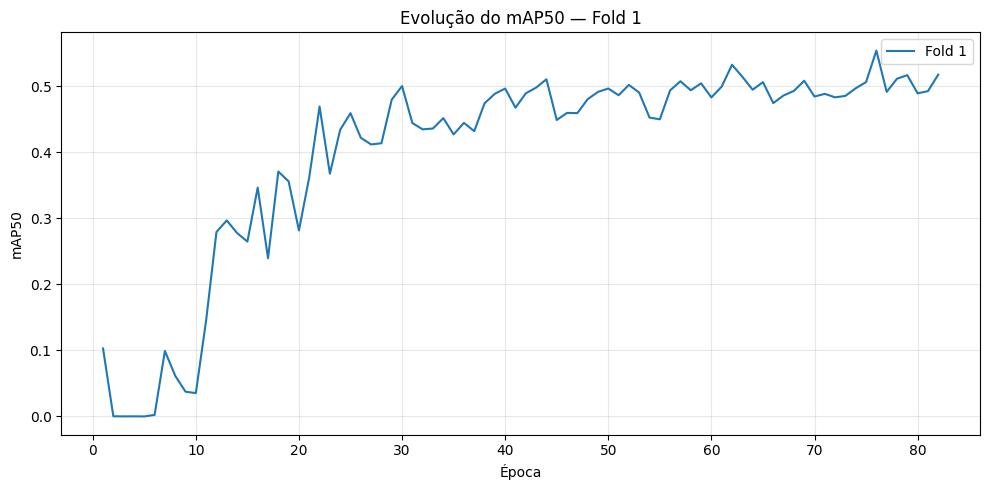

Fold 2 — últimas épocas:


,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
83,84,1019.11,1.40775,1.03699,1.39902,0.58549,0.44444,0.41956,0.18541,2.03888,1.83904,1.99971,0.000357,0.000357,0.000357
84,85,1031.20,1.37778,1.06048,1.39874,0.55547,0.46825,0.41274,0.18882,2.04387,1.74141,1.99422,0.000337,0.000337,0.000337
85,86,1043.14,1.38281,1.02013,1.33594,0.51489,0.47174,0.41339,0.18509,2.02844,1.77316,1.97172,0.000317,0.000317,0.000317


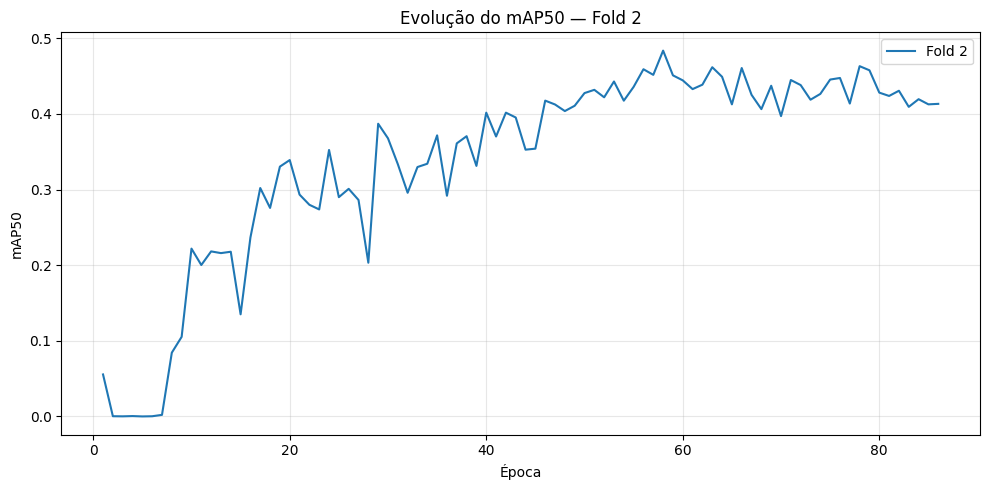

Fold 3 — últimas épocas:


,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
63,64,814.880,1.58091,1.16698,1.45508,0.74939,0.53465,0.58985,0.29376,1.99663,1.62410,1.80238,0.000753,0.000753,0.000753
64,65,827.190,1.55514,1.17338,1.45405,0.74520,0.56436,0.62308,0.29849,1.99730,1.52768,1.78876,0.000733,0.000733,0.000733
65,66,839.627,1.55873,1.17232,1.43538,0.77249,0.57153,0.64169,0.31206,1.92047,1.51533,1.72953,0.000713,0.000713,0.000713


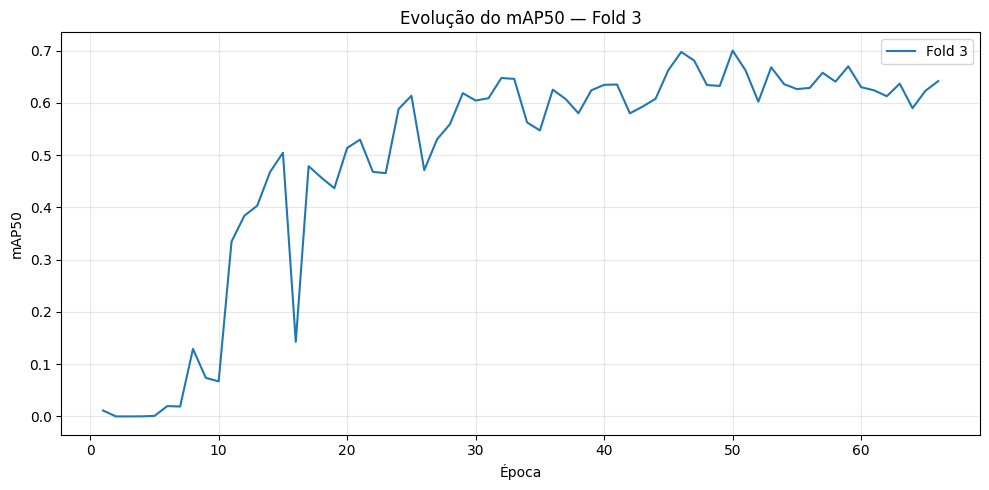

Fold 4 — últimas épocas:


,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
75,76,944.583,1.41602,1.10021,1.39766,0.65055,0.54867,0.53099,0.23623,2.07468,1.60121,1.99133,0.000515,0.000515,0.000515
76,77,956.524,1.41655,1.14773,1.39856,0.62227,0.55401,0.51541,0.23064,2.12115,1.60604,1.99541,0.000495,0.000495,0.000495
77,78,968.573,1.44057,1.09253,1.37791,0.69394,0.51327,0.55574,0.23891,2.06625,1.66291,1.92553,0.000475,0.000475,0.000475


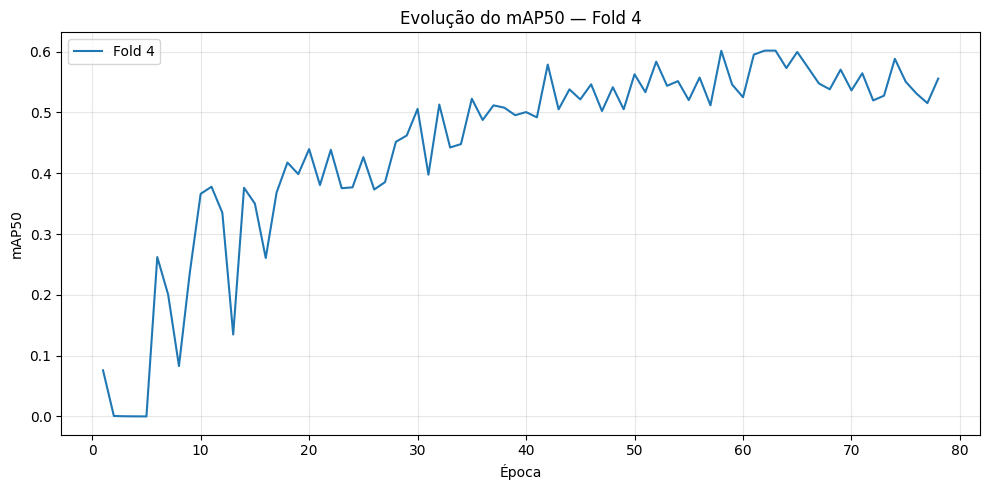

Fold 5 — últimas épocas:


,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
89,90,1103.92,1.38535,1.03067,1.38923,0.62152,0.37121,0.42393,0.17338,2.08423,1.29348,1.81000,0.000238,0.000238,0.000238
90,91,1115.82,1.34429,1.04028,1.39372,0.55103,0.40909,0.41792,0.17701,2.11542,1.35267,1.86236,0.000218,0.000218,0.000218
91,92,1127.27,1.35164,0.98687,1.36504,0.64784,0.42424,0.43216,0.19135,2.11155,1.34073,1.87876,0.000198,0.000198,0.000198


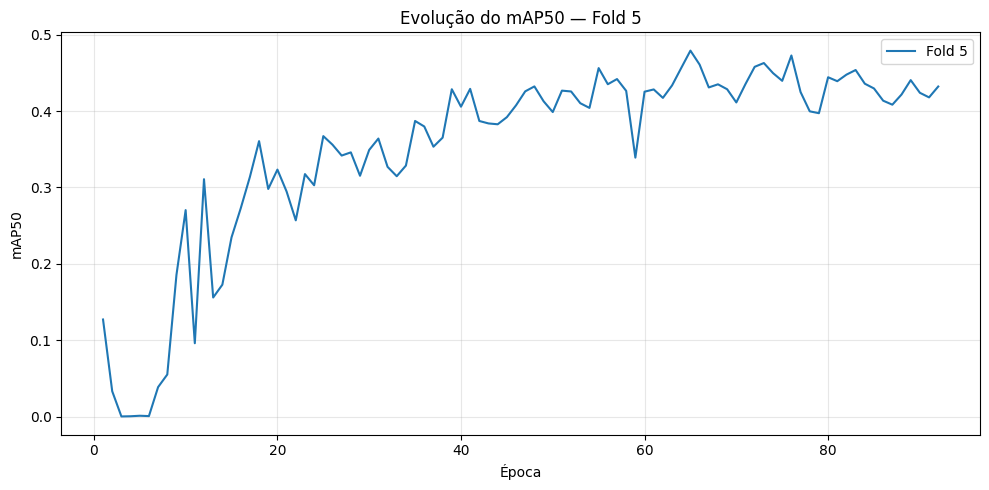

In [27]:
import pandas as pd
import matplotlib.pyplot as plt

# ===== CURVAS DOS 5 FOLDS =====

for fold_number in range(1, N_FOLDS + 1):
    results_csv = Path(RESULTS_ROOT) / f"fold_{fold_number}" / "results.csv"

    if not results_csv.exists():
        print(f"results.csv não encontrado para Fold {fold_number}.")
        continue

    history = pd.read_csv(results_csv)

    print(f"Fold {fold_number} — últimas épocas:")
    display(history.tail(3))

    if "metrics/mAP50(B)" in history.columns:
        plt.figure(figsize=(10, 5))
        plt.plot(
            history["epoch"],
            history["metrics/mAP50(B)"],
            label=f"Fold {fold_number}"
        )
        plt.xlabel("Época")
        plt.ylabel("mAP50")
        plt.title(f"Evolução do mAP50 — Fold {fold_number}")
        plt.grid(alpha=0.3)
        plt.legend()
        plt.tight_layout()
        plt.show()

## 10. Avaliação por caixa no fold de teste

A avaliação de cada rodada é feita somente no **fold externo de teste** correspondente.

Serão registrados:

- Precision;
- Recall;
- mAP50;
- mAP50-95.

Essas métricas são calculadas no nível de **caixa delimitadora (box-level)**.


In [28]:
# ===== AVALIAÇÃO BOX-LEVEL NOS TESTES EXTERNOS =====

box_results = []

for fold_cfg, train_info in zip(fold_configs, fold_training_info):
    fold_number = fold_cfg["fold"]
    best_model_path = train_info["best_model"]
    data_yaml = str(fold_cfg["yaml"])

    print("\n" + "=" * 70)
    print(f"AVALIAÇÃO BOX-LEVEL — FOLD {fold_number}")
    print("=" * 70)

    best_model = YOLO(best_model_path)

    metrics = best_model.val(
        data=data_yaml,
        split="test",
        imgsz=IMGSZ,
        plots=True,
        verbose=False
    )

    row = {
        "fold": fold_number,
        "Precisão": metrics.results_dict.get("metrics/precision(B)"),
        "Recall": metrics.results_dict.get("metrics/recall(B)"),
        "mAP50": metrics.results_dict.get("metrics/mAP50(B)"),
        "mAP50-95": metrics.results_dict.get("metrics/mAP50-95(B)")
    }

    box_results.append(row)

box_results_df = pd.DataFrame(box_results)

print("\nResultados por fold:")
display(box_results_df)

print("\nMédia e desvio padrão:")
display(
    box_results_df[["Precisão", "Recall", "mAP50", "mAP50-95"]]
    .agg(["mean", "std"])
)



AVALIAÇÃO BOX-LEVEL — FOLD 1
Ultralytics 8.4.142 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 100 layers, 9,413,187 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 60.8±40.1 MB/s, size: 126.4 KB)
val: Scanning /content/dataset_shark_binary_5fold/cv_folds/fold_1/labels/test... 108 images, 18 backgrounds, 1 corrupt: 100% ━━━━━━━━━━━━ 108/108 867.9it/s 0.1s
val: /content/dataset_shark_binary_5fold/cv_folds/fold_1/images/test/95c5fbf5-00621.png: ignoring corrupt image/label: non-normalized or out of bounds coordinates [1.1726749]
val: New cache created: /content/dataset_shark_binary_5fold/cv_folds/fold_1/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 2.8it/s 2.5s
                   all        107        146      0.545        0.5       0.48      0.204
Speed: 4.1ms preprocess, 9.9ms inference, 0.0ms loss, 2.8ms postprocess per 

,fold,Precisão,Recall,mAP50,mAP50-95
0,1,0.545166,0.500000,0.479662,0.204115
1,2,0.647450,0.646181,0.637171,0.299243
2,3,0.588197,0.428571,0.416779,0.175650
3,4,0.643528,0.408257,0.425735,0.168171
4,5,0.637052,0.592129,0.580238,0.277578



Média e desvio padrão:


,Precisão,Recall,mAP50,mAP50-95
mean,0.612279,0.515028,0.507917,0.224951
std,0.044473,0.102770,0.097205,0.059954


## 11. Avaliação binária por imagem: tubarão presente ou ausente

Além da avaliação tradicional por caixa, o estudo de caso responde diretamente à pergunta:

> **A imagem contém um tubarão ou não contém um tubarão?**

Para cada imagem do fold de teste:

- **Real = tubarão:** existe pelo menos uma anotação de tubarão;
- **Real = não-tubarão:** o arquivo de label está vazio;
- **Predito = tubarão:** o modelo detecta pelo menos uma caixa acima do limiar de confiança;
- **Predito = não-tubarão:** nenhuma caixa ultrapassa o limiar.

A partir dessas decisões são calculados:

- TP — verdadeiro positivo;
- FP — falso positivo;
- FN — falso negativo;
- TN — verdadeiro negativo;
- acurácia;
- precisão;
- recall;
- F1-score.

O limiar utilizado é `CONF_THRESHOLD = 0.50`.


In [29]:
# ===== CLASSIFICAÇÃO BINÁRIA POR IMAGEM EM CADA FOLD =====

CONF_THRESHOLD = 0.50

binary_rows = []
fold_binary_metrics = []

for fold_cfg, train_info in zip(fold_configs, fold_training_info):
    fold_number = fold_cfg["fold"]
    best_model_path = train_info["best_model"]

    best_model = YOLO(best_model_path)

    test_img_dir = Path(DATASET) / "cv_folds" / f"fold_{fold_number}" / "images" / "test"
    test_label_dir = Path(DATASET) / "cv_folds" / f"fold_{fold_number}" / "labels" / "test"

    image_files = sorted([
        p for p in test_img_dir.iterdir()
        if p.suffix.lower() in IMAGE_EXTS
    ])

    TP = FP = FN = TN = 0

    for img_path in image_files:
        label_path = test_label_dir / f"{img_path.stem}.txt"

        text = label_path.read_text(encoding="utf-8").strip() if label_path.exists() else ""
        ground_truth = "tubarao" if text else "nao_tubarao"

        preds = best_model.predict(
            source=str(img_path),
            conf=CONF_THRESHOLD,
            verbose=False
        )

        n_detections = len(preds[0].boxes)
        predicted = "tubarao" if n_detections > 0 else "nao_tubarao"

        if ground_truth == "tubarao" and predicted == "tubarao":
            TP += 1
        elif ground_truth == "nao_tubarao" and predicted == "tubarao":
            FP += 1
        elif ground_truth == "tubarao" and predicted == "nao_tubarao":
            FN += 1
        elif ground_truth == "nao_tubarao" and predicted == "nao_tubarao":
            TN += 1

        binary_rows.append({
            "fold": fold_number,
            "image": img_path.name,
            "ground_truth": ground_truth,
            "predicted": predicted,
            "n_detections": n_detections
        })

    total = TP + FP + FN + TN

    accuracy = (TP + TN) / total if total > 0 else np.nan
    precision = TP / (TP + FP) if (TP + FP) > 0 else np.nan
    recall = TP / (TP + FN) if (TP + FN) > 0 else np.nan
    f1 = (
        2 * precision * recall / (precision + recall)
        if np.isfinite(precision) and np.isfinite(recall) and (precision + recall) > 0
        else np.nan
    )

    fold_binary_metrics.append({
        "fold": fold_number,
        "TP": TP,
        "FP": FP,
        "FN": FN,
        "TN": TN,
        "Acurácia": accuracy,
        "Precisão": precision,
        "Recall": recall,
        "F1": f1
    })

binary_df = pd.DataFrame(binary_rows)
fold_binary_df = pd.DataFrame(fold_binary_metrics)

print("===== RESULTADOS BINÁRIOS POR FOLD =====")
display(fold_binary_df)


===== RESULTADOS BINÁRIOS POR FOLD =====


,fold,TP,FP,FN,TN,Acurácia,Precisão,Recall,F1
0,1,35,0,55,18,0.490741,1.000000,0.388889,0.560000
1,2,56,2,33,16,0.672897,0.965517,0.629213,0.761905
2,3,59,2,30,16,0.700935,0.967213,0.662921,0.786667
3,4,52,1,37,16,0.641509,0.981132,0.584270,0.732394
4,5,61,2,28,15,0.716981,0.968254,0.685393,0.802632


## 12. Matriz de confusão por fold e matriz agregada

A matriz de confusão mostra os quatro tipos de decisão possíveis.

Como cada imagem é testada exatamente uma vez durante o 5-Fold Cross-Validation, também é possível construir uma **matriz de confusão agregada**, reunindo as previsões das cinco rodadas.


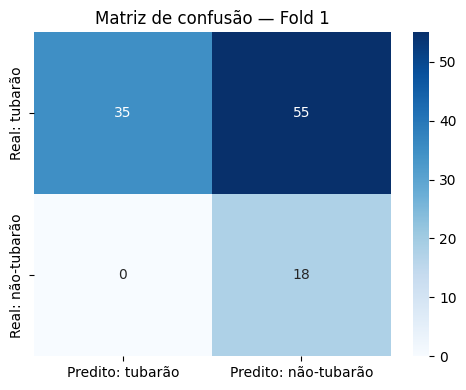

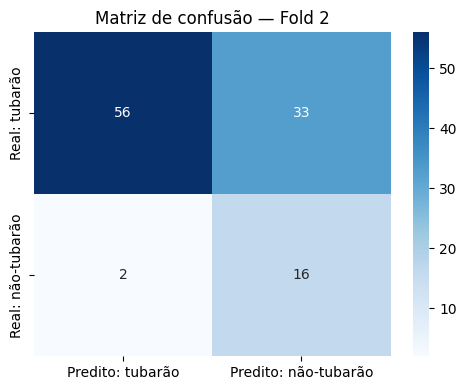

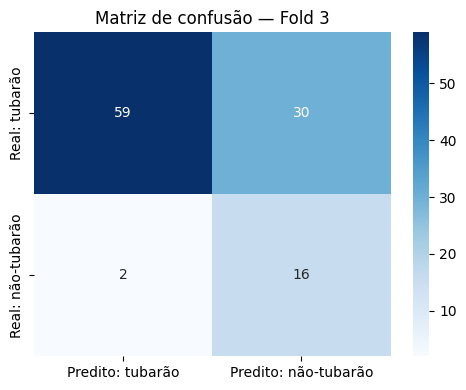

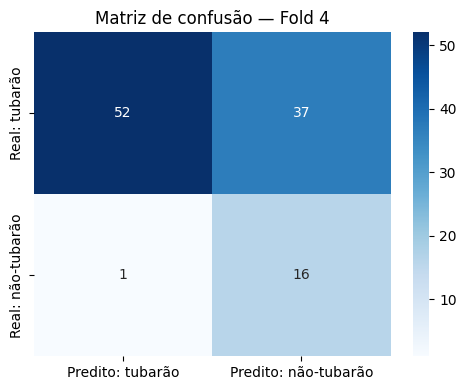

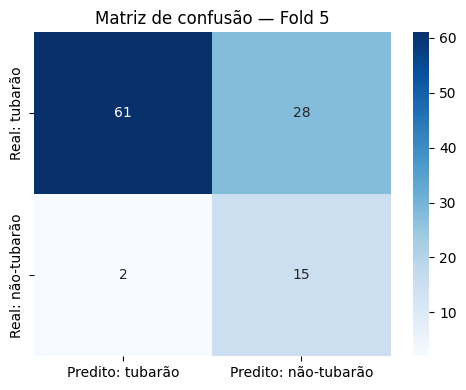

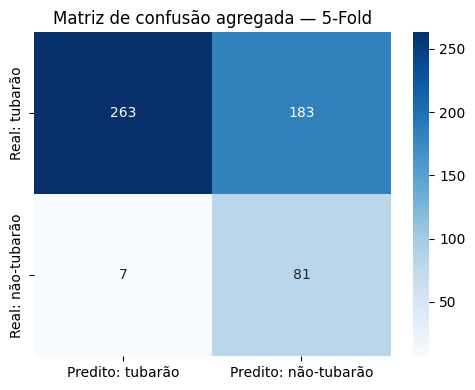

===== MÉTRICAS BINÁRIAS AGREGADAS — 5-FOLD =====
TP: 263
FP: 7
FN: 183
TN: 81
Acurácia: 0.644
Precisão: 0.974
Recall: 0.590
F1: 0.735


In [31]:
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

# ===== MATRIZES DE CONFUSÃO =====

for _, row in fold_binary_df.iterrows():
    confusion = np.array([
        [row["TP"], row["FN"]],
        [row["FP"], row["TN"]]
    ])

    plt.figure(figsize=(5, 4))
    sns.heatmap(
        confusion,
        annot=True,
        fmt="g",
        cmap="Blues",
        xticklabels=["Predito: tubarão", "Predito: não-tubarão"],
        yticklabels=["Real: tubarão", "Real: não-tubarão"]
    )
    plt.title(f"Matriz de confusão — Fold {int(row['fold'])}")
    plt.tight_layout()
    plt.show()

TP_total = int(fold_binary_df["TP"].sum())
FP_total = int(fold_binary_df["FP"].sum())
FN_total = int(fold_binary_df["FN"].sum())
TN_total = int(fold_binary_df["TN"].sum())

confusion_total = np.array([
    [TP_total, FN_total],
    [FP_total, TN_total]
])

plt.figure(figsize=(5, 4))
sns.heatmap(
    confusion_total,
    annot=True,
    fmt="g",
    cmap="Blues",
    xticklabels=["Predito: tubarão", "Predito: não-tubarão"],
    yticklabels=["Real: tubarão", "Real: não-tubarão"]
)
plt.title("Matriz de confusão agregada — 5-Fold")
plt.tight_layout()
plt.show()

total_images = TP_total + FP_total + FN_total + TN_total

accuracy_total = (TP_total + TN_total) / total_images
precision_total = TP_total / (TP_total + FP_total) if (TP_total + FP_total) > 0 else np.nan
recall_total = TP_total / (TP_total + FN_total) if (TP_total + FN_total) > 0 else np.nan
f1_total = (
    2 * precision_total * recall_total / (precision_total + recall_total)
    if np.isfinite(precision_total) and np.isfinite(recall_total)
    and (precision_total + recall_total) > 0
    else np.nan
)

aggregate_binary_metrics = {
    "TP": TP_total,
    "FP": FP_total,
    "FN": FN_total,
    "TN": TN_total,
    "Acurácia": accuracy_total,
    "Precisão": precision_total,
    "Recall": recall_total,
    "F1": f1_total
}

print("===== MÉTRICAS BINÁRIAS AGREGADAS — 5-FOLD =====")
for k, v in aggregate_binary_metrics.items():
    if isinstance(v, (float, np.floating)):
        print(f"{k}: {v:.3f}")
    else:
        print(f"{k}: {v}")

## 13. Análise visual das detecções

São apresentados exemplos dos quatro tipos de resultado:

- **Verdadeiros positivos:** tubarão presente e detectado;
- **Falsos positivos:** modelo detecta tubarão em uma imagem sem tubarão;
- **Falsos negativos:** tubarão presente, mas não detectado;
- **Verdadeiros negativos:** imagem sem tubarão corretamente classificada.

Os exemplos são obtidos a partir das previsões realizadas nos **folds de teste**, mantendo a separação entre treino e teste.


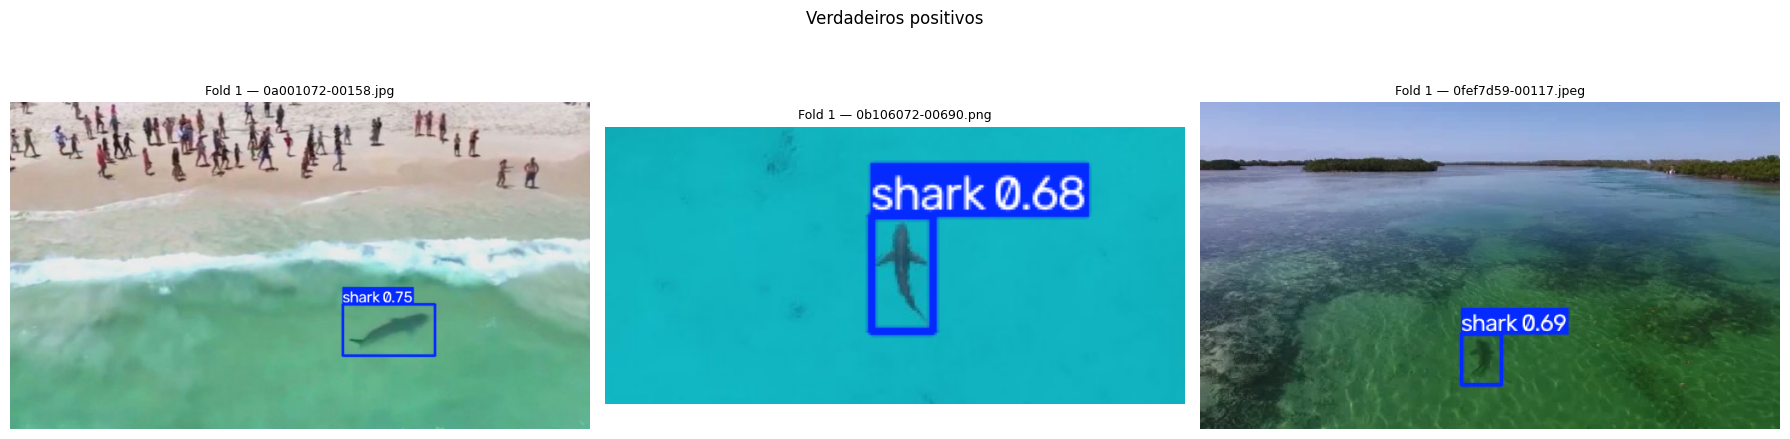

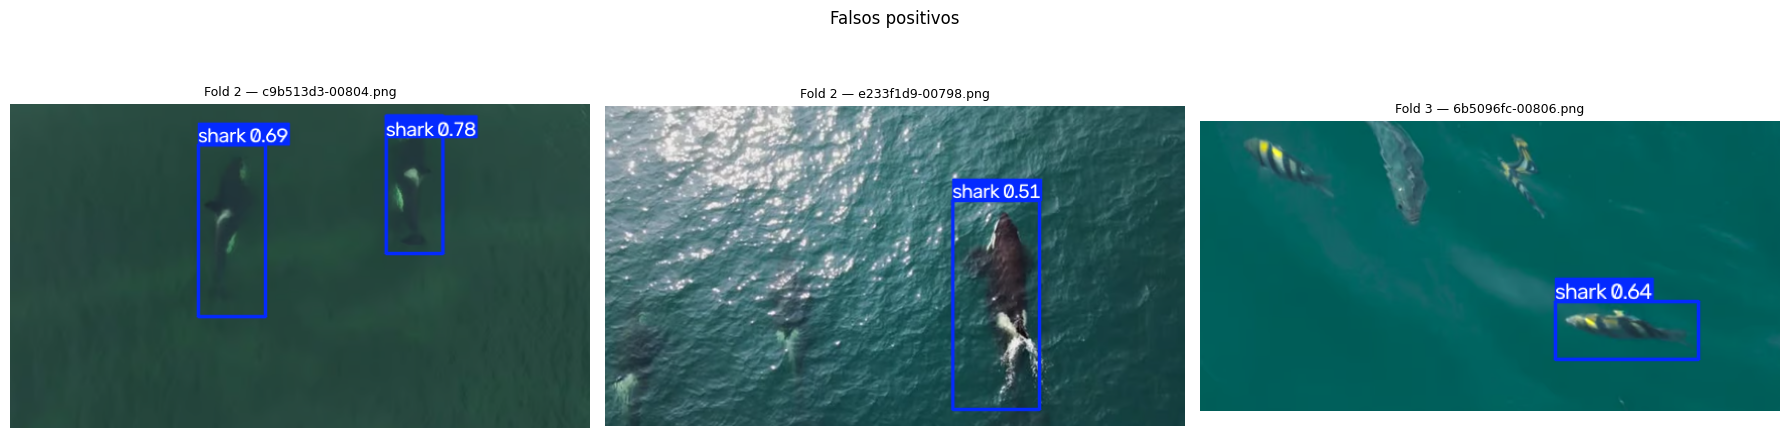

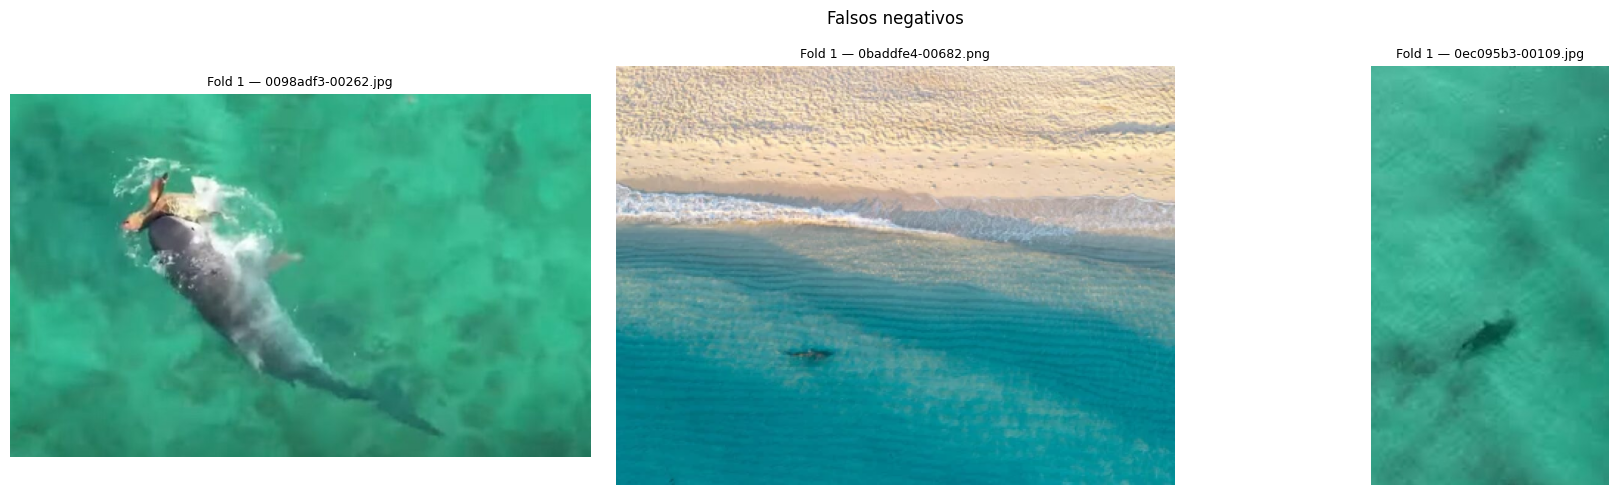

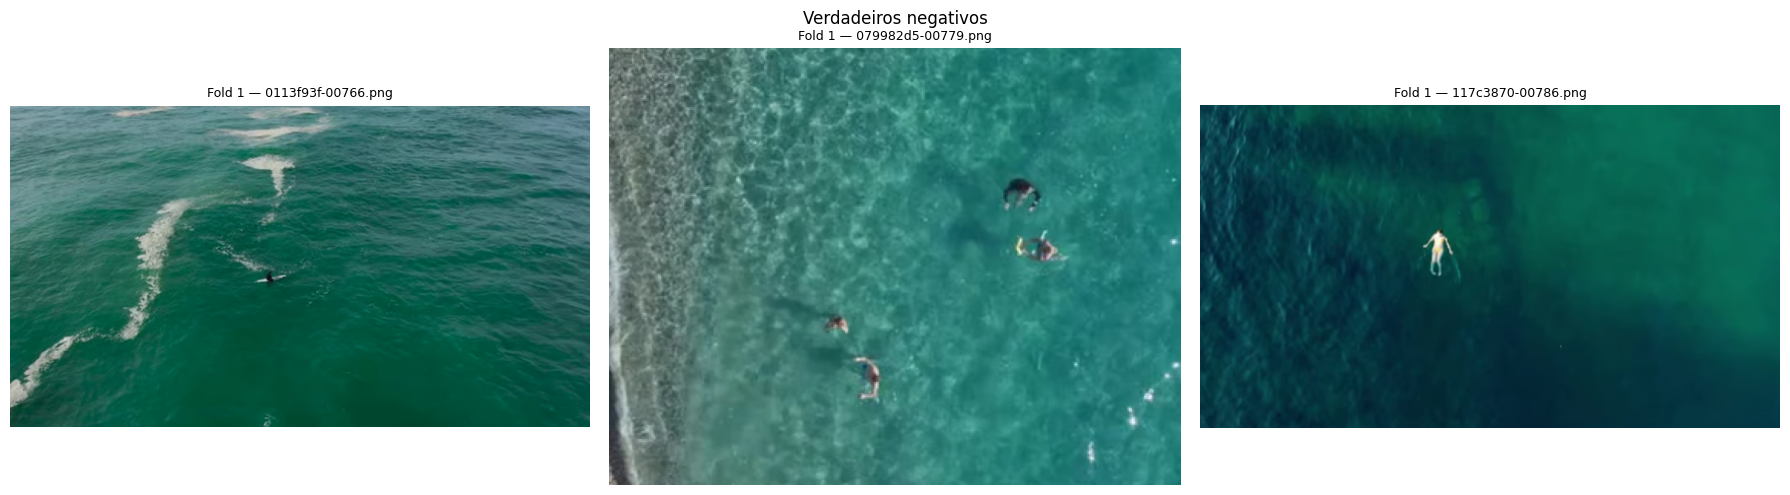

In [33]:
# ===== EXEMPLOS VISUAIS DOS RESULTADOS =====

def plot_examples(category_df, title, n=3):
    sample = category_df.head(n)

    if sample.empty:
        print(f"Nenhum exemplo disponível para: {title}")
        return

    fig, axes = plt.subplots(
        1,
        len(sample),
        figsize=(6 * len(sample), 5)
    )

    if len(sample) == 1:
        axes = [axes]

    for ax, (_, row) in zip(axes, sample.iterrows()):
        fold_number = int(row["fold"])

        img_path = (
            Path(DATASET)
            / "cv_folds"
            / f"fold_{fold_number}"
            / "images"
            / "test"
            / row["image"]
        )

        model_path = next(
            item["best_model"]
            for item in fold_training_info
            if item["fold"] == fold_number
        )

        model = YOLO(model_path)

        preds = model.predict(
            source=str(img_path),
            conf=CONF_THRESHOLD,
            verbose=False
        )

        annotated = preds[0].plot()
        annotated = cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB)

        ax.imshow(annotated)
        ax.set_title(
            f"Fold {fold_number} — {row['image']}",
            fontsize=9
        )
        ax.axis("off")

    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

tp_df = binary_df[
    (binary_df.ground_truth == "tubarao") &
    (binary_df.predicted == "tubarao")
]

fp_df = binary_df[
    (binary_df.ground_truth == "nao_tubarao") &
    (binary_df.predicted == "tubarao")
]

fn_df = binary_df[
    (binary_df.ground_truth == "tubarao") &
    (binary_df.predicted == "nao_tubarao")
]

tn_df = binary_df[
    (binary_df.ground_truth == "nao_tubarao") &
    (binary_df.predicted == "nao_tubarao")
]

plot_examples(tp_df, "Verdadeiros positivos")
plot_examples(fp_df, "Falsos positivos")
plot_examples(fn_df, "Falsos negativos")
plot_examples(tn_df, "Verdadeiros negativos")


## 14. Comparação dos cinco folds

A validação cruzada permite observar a variação do desempenho entre as diferentes partições.

O resultado final deve considerar a **média e o desvio padrão** dos cinco folds, além dos resultados de cada rodada.


Média e desvio padrão — classificação binária:


,Acurácia,Precisão,Recall,F1
mean,0.644613,0.976423,0.590137,0.728719
std,0.090686,0.014565,0.118779,0.097982


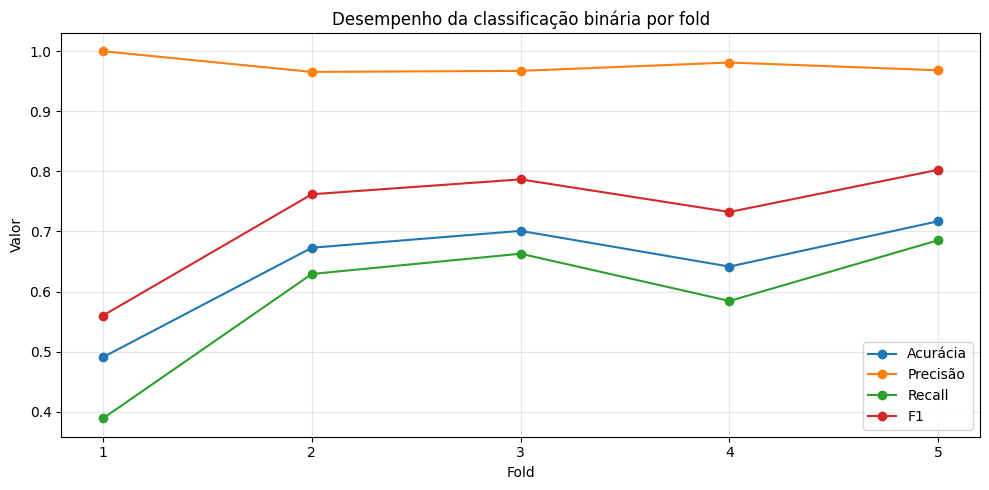

In [34]:
# ===== RESUMO ESTATÍSTICO DOS 5 FOLDS =====

summary_metrics = fold_binary_df[
    ["Acurácia", "Precisão", "Recall", "F1"]
].agg(["mean", "std"])

print("Média e desvio padrão — classificação binária:")
display(summary_metrics)

plt.figure(figsize=(10, 5))

for metric in ["Acurácia", "Precisão", "Recall", "F1"]:
    plt.plot(
        fold_binary_df["fold"],
        fold_binary_df[metric],
        marker="o",
        label=metric
    )

plt.xticks(range(1, N_FOLDS + 1))
plt.xlabel("Fold")
plt.ylabel("Valor")
plt.title("Desempenho da classificação binária por fold")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


## 15. Teste aplicado em vídeo

O vídeo é apresentado somente como **demonstração da aplicação prática** do detector.

Ele não participa da validação cruzada e não deve ser utilizado para calcular as métricas do estudo.

Para evitar escolher um modelo com base no desempenho do conjunto de teste, o caminho do modelo utilizado no vídeo deve ser definido de forma independente da avaliação.


In [35]:
# ===== DETECÇÃO EM VÍDEO =====

VIDEO_PATH = "/content/video.mp4"

# Escolha manualmente um modelo para demonstração.
# Não selecione automaticamente o fold com maior desempenho no teste.
MODEL_FOR_VIDEO = "/content/results/drone_shark_binary_5fold/fold_1/weights/best.pt"

if os.path.exists(VIDEO_PATH) and os.path.exists(MODEL_FOR_VIDEO):
    video_model = YOLO(MODEL_FOR_VIDEO)

    video_results = video_model.predict(
        source=VIDEO_PATH,
        conf=CONF_THRESHOLD,
        save=True,
        project="/content/video_results",
        name="drone_shark_binary_5fold",
        exist_ok=True
    )

    print("Vídeo processado.")
    print("Resultados salvos em /content/video_results")
else:
    print("Vídeo ou modelo não encontrado.")
    print("Altere VIDEO_PATH e MODEL_FOR_VIDEO para executar esta etapa.")



WARNING ⚠️ 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

video 1/1 (frame 1/1086) /content/video.mp4: 384x640 1 shark, 10.5ms
video 1/1 (frame 2/1086) /content/video.mp4: 384x640 1 shark, 10.8ms
video 1/1 (frame 3/1086) /content/video.mp4: 384x640 1 shark, 11.4ms
video 1/1 (frame 4/1086) /content/video.mp4: 384x640 1 shark, 10.5ms
video 1/1 (frame 5/1086) /content/video.mp4: 384x640 1 shark, 10.6ms
video 1/1 (frame 6/1086) /content/video.mp4: 384x640 1 shark, 12.6ms
video 1/1 (frame 7/1086) /content/video.mp4: 

## 16. Exportação dos resultados

As tabelas principais são salvas para utilização no TCC.

São exportados:

- métricas box-level de cada fold;
- métricas binárias de cada fold;
- métricas binárias agregadas;
- previsões por imagem;
- resumo estatístico do 5-Fold.


In [36]:
# ===== EXPORTAR RESULTADOS =====

EXPORT_DIR = Path("/content/resultados_drone_shark_5fold")
EXPORT_DIR.mkdir(parents=True, exist_ok=True)

box_results_df.to_csv(
    EXPORT_DIR / "resultados_box_level_5fold.csv",
    index=False,
    encoding="utf-8-sig"
)

fold_binary_df.to_csv(
    EXPORT_DIR / "resultados_binarios_por_fold.csv",
    index=False,
    encoding="utf-8-sig"
)

pd.DataFrame([aggregate_binary_metrics]).to_csv(
    EXPORT_DIR / "resultados_binarios_agregados.csv",
    index=False,
    encoding="utf-8-sig"
)

binary_df.to_csv(
    EXPORT_DIR / "predicoes_por_imagem_5fold.csv",
    index=False,
    encoding="utf-8-sig"
)

summary_metrics.to_csv(
    EXPORT_DIR / "resumo_media_desvio_5fold.csv",
    encoding="utf-8-sig"
)

print("Arquivos gerados em:", EXPORT_DIR)
for p in sorted(EXPORT_DIR.iterdir()):
    print(" -", p.name)


Arquivos gerados em: /content/resultados_drone_shark_5fold
 - predicoes_por_imagem_5fold.csv
 - resultados_binarios_agregados.csv
 - resultados_binarios_por_fold.csv
 - resultados_box_level_5fold.csv
 - resumo_media_desvio_5fold.csv


# 17. Estrutura para interpretação dos resultados

Ao finalizar a execução, o capítulo do TCC pode ser organizado em:

1. **Ambiente experimental** — Google Colab, GPU, Python e Ultralytics YOLO.
2. **Preparação da base** — filtragem para classe única (`shark`) e manutenção das imagens sem tubarão como background.
3. **Validação cruzada 5-Fold** — em cada rodada, quatro folds são destinados ao desenvolvimento e um fold é reservado exclusivamente para teste.
4. **Treinamento** — YOLO11s com hiperparâmetros fixos em todas as cinco rodadas.
5. **Avaliação box-level** — Precision, Recall, mAP50 e mAP50-95 no fold externo de teste.
6. **Avaliação binária por imagem** — matriz de confusão, acurácia, precisão, recall e F1.
7. **Resultado agregado** — média e desvio padrão dos cinco folds.
8. **Análise visual** — verdadeiros positivos, falsos positivos, falsos negativos e verdadeiros negativos.
9. **Aplicação em vídeo** — demonstração prática, sem participação no cálculo das métricas.

### Hipótese de interpretação

O 5-Fold Cross-Validation permite verificar se o desempenho do detector permanece consistente quando diferentes grupos de imagens são retirados do treinamento e utilizados como teste.

Um resultado com **média elevada e desvio padrão baixo** indica maior estabilidade entre as partições.

Um resultado com **grande variação entre folds** indica que o desempenho depende mais fortemente da composição do conjunto de imagens utilizado em cada rodada.

**Não se deve escolher ou descartar folds apenas para produzir um resultado esperado.** Todos os cinco folds devem ser reportados.
